rewards [-20.           1.82318492   2.94124645 ...   9.41551256   1.90829203
   6.59674449]


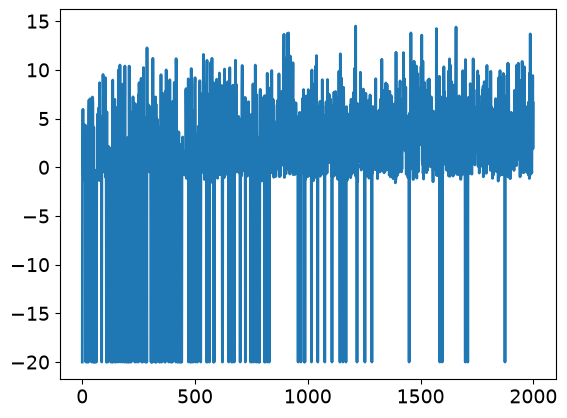

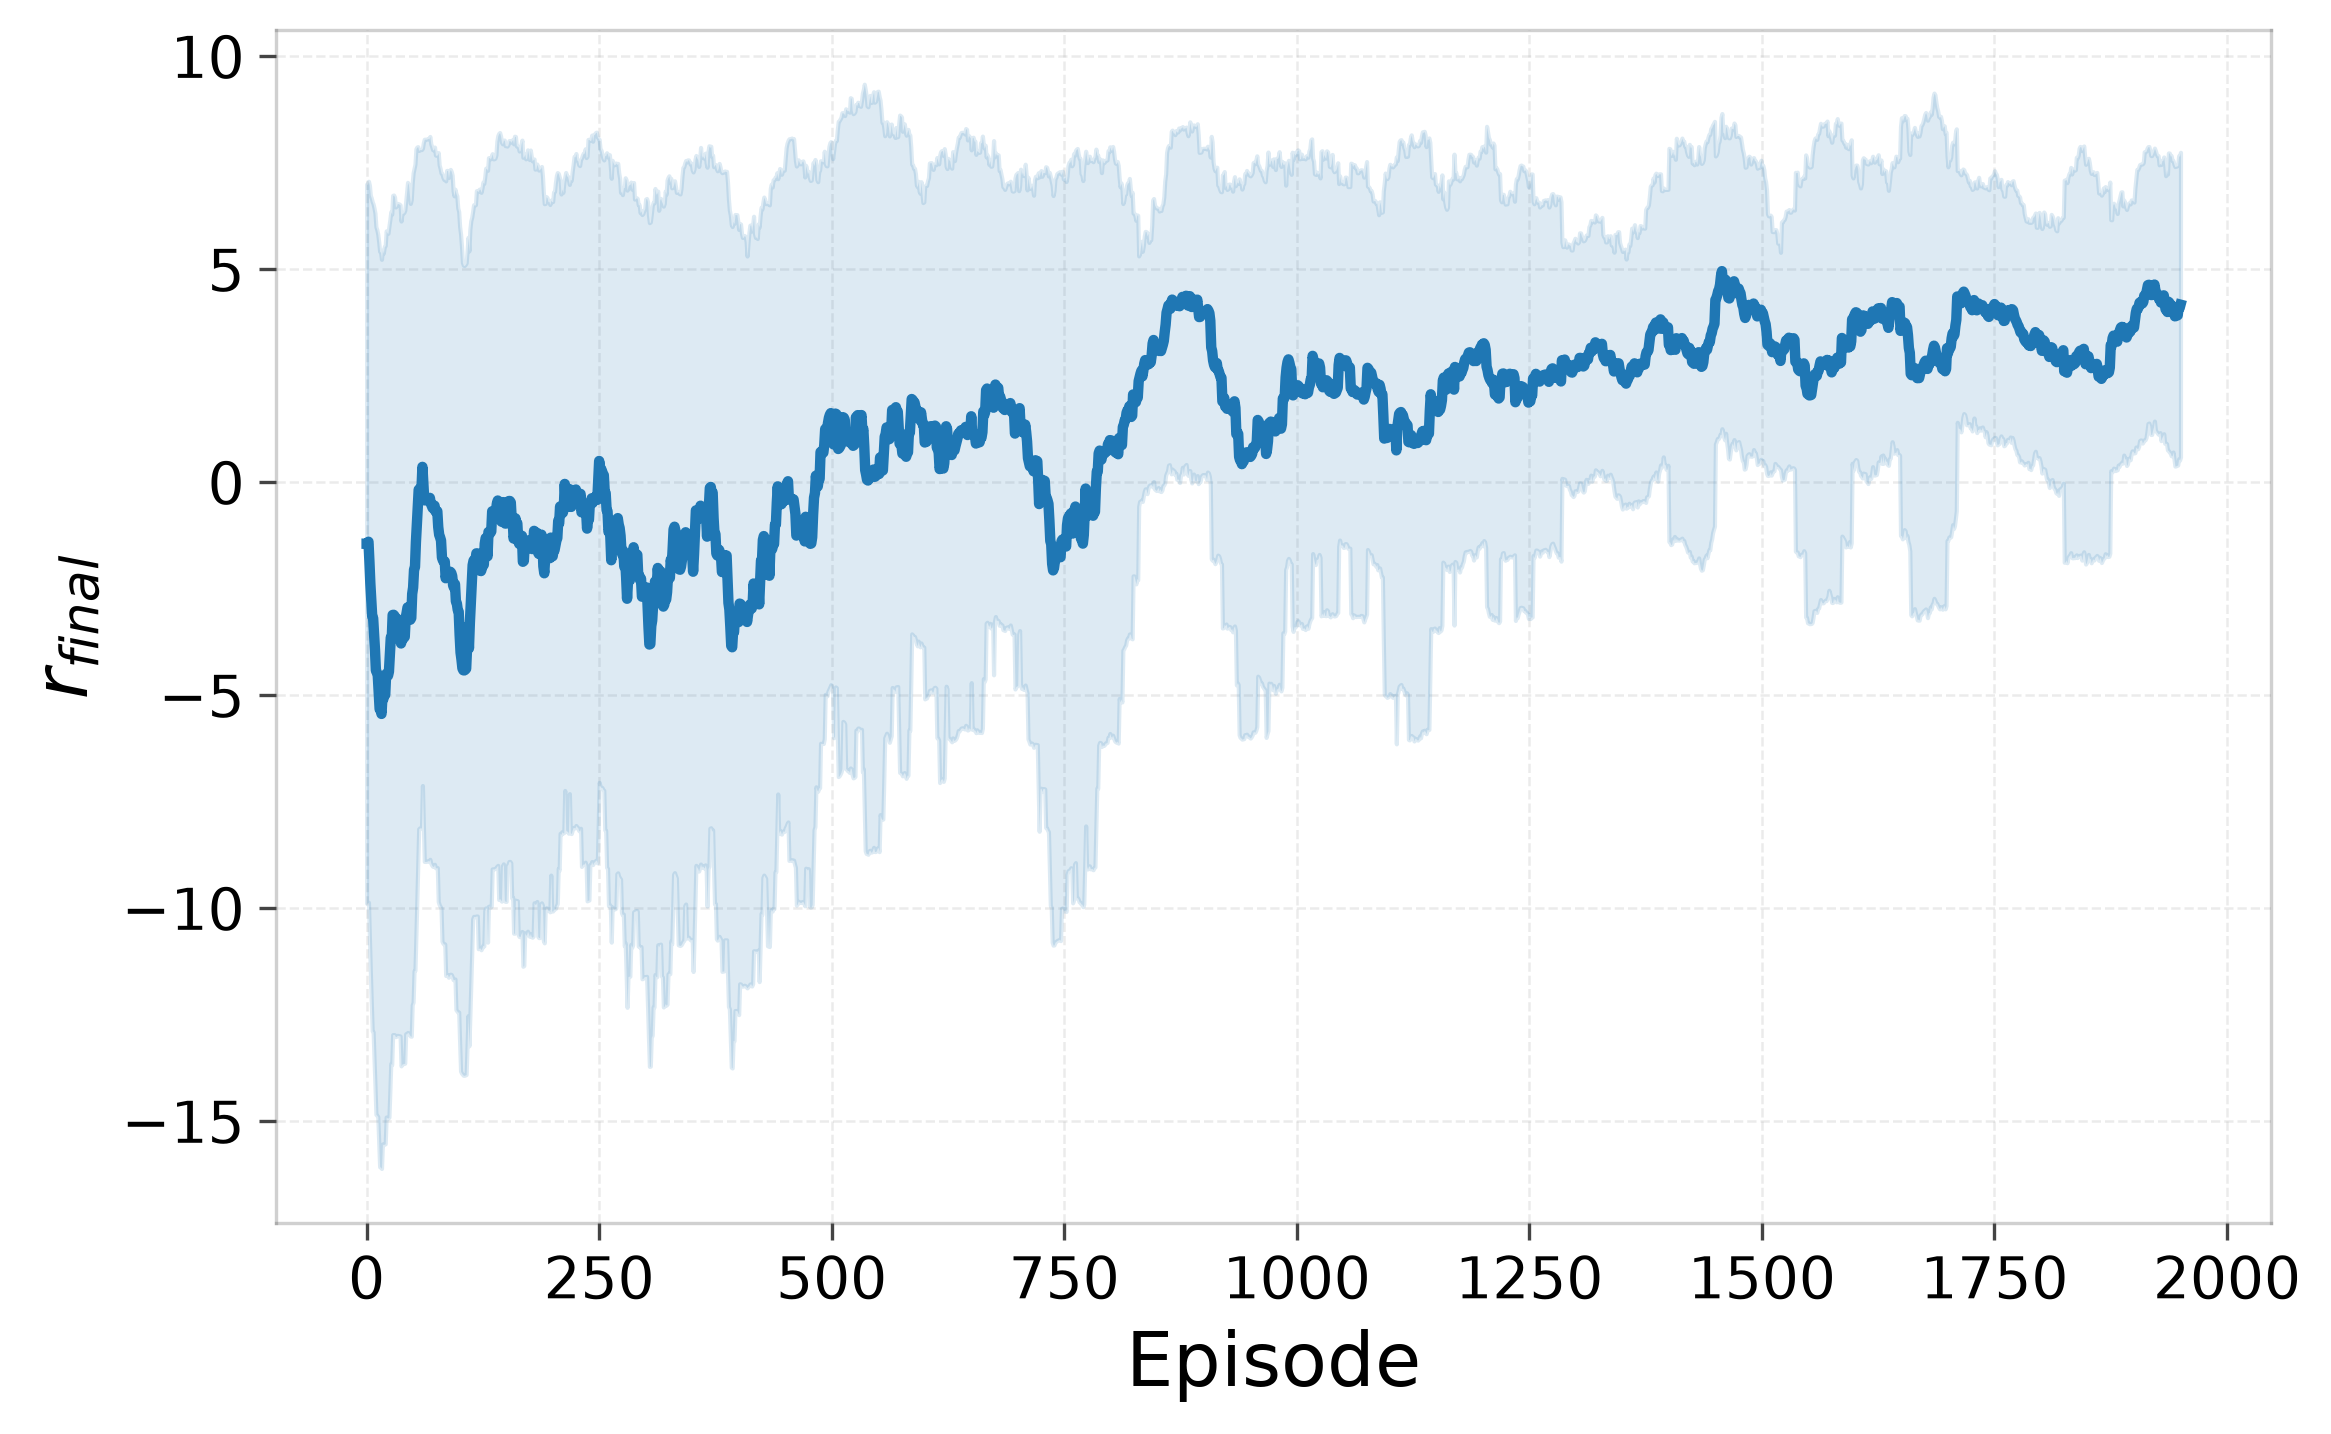

In [54]:
##Based on the originality without bias, classify the structures based on the bandgap
import numpy as np
import matplotlib.pyplot as plt
import random
import sys
sys.path.append("..")

from utils.utils import build_p4m_structure_simple, strictly_enforce_4_connectivity, get_fundamental_grid

loadData = np.load("SAC_DISCRETE_without_PER_history.npy",allow_pickle=True)
ep = loadData[0]
#states = ep['states']
##actions = ep['actions']
##rewards = ep['rewards']
#bandgap = ep['bandgap']
final_reward = ep['final_bandgap_reward']
#print("states", rewards)

bandgaps= [val['bandgap'] for val in loadData]
rewards = np.array([val['final_bandgap_reward'] for val in loadData])
print('rewards', rewards)
#rewards = np.sum(rewards, axis=1)
#rewards_arr = np.array(rewards)/500
#print(rewards_arr)
plt.plot(rewards)
idx= np.where(rewards >4)[0]
idx = np.random.choice(idx, 100)

# print(idx)

#states = [val['states'] for val in loadData]
#states = [np.array(state) for state in states]
#states = np.array(states)[idx]

#bandgaps= [np.array(x) for x in bandgaps]
#bandgaps = [bandgaps[i] for i in idx]
#print(np.shape(states)) #path
#print(np.shape(bandgaps))

#######################
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "legend.fontsize": 14,
    "lines.linewidth": 2})
############################

window = 50
def moving_average(x, w):
    return np.convolve(x, np.ones(w)/w, mode='valid')

def moving_std(x, w):
    return np.array([np.std(x[i:i+w]) for i in range(len(x)-w+1)])

ma = moving_average(rewards, window)
std = moving_std(rewards, window)

episodes = np.arange(len(ma))

upper = ma + std
lower = ma - std

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
ax.plot(episodes, ma, linewidth=2.5, color="#1f77b4")
ax.fill_between(episodes, lower, upper, alpha=0.15, color="#1f77b4")

ax.set_xlabel("Episode", fontsize=18)
ax.set_ylabel(r"$r_{final}$", fontsize=18)

ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.25)
ax.set_axisbelow(True)
#more of annotation, can be removed)
for spine in ax.spines.values():
    spine.set_linewidth(0.8)
    spine.set_color("#444444")
    spine.set_alpha(0.25)

ax.tick_params(axis="both", which="major",
               labelsize=14,
               length=4,
               width=0.8,
               color="#444444")

ax.tick_params(top=False, right=False)

plt.tight_layout()
#plt.savefig("Updated_SAC_DISCRETE_training_data_WO_frame_history.png", dpi=500, bbox_inches='tight')
#plt.close()
#######################################################################

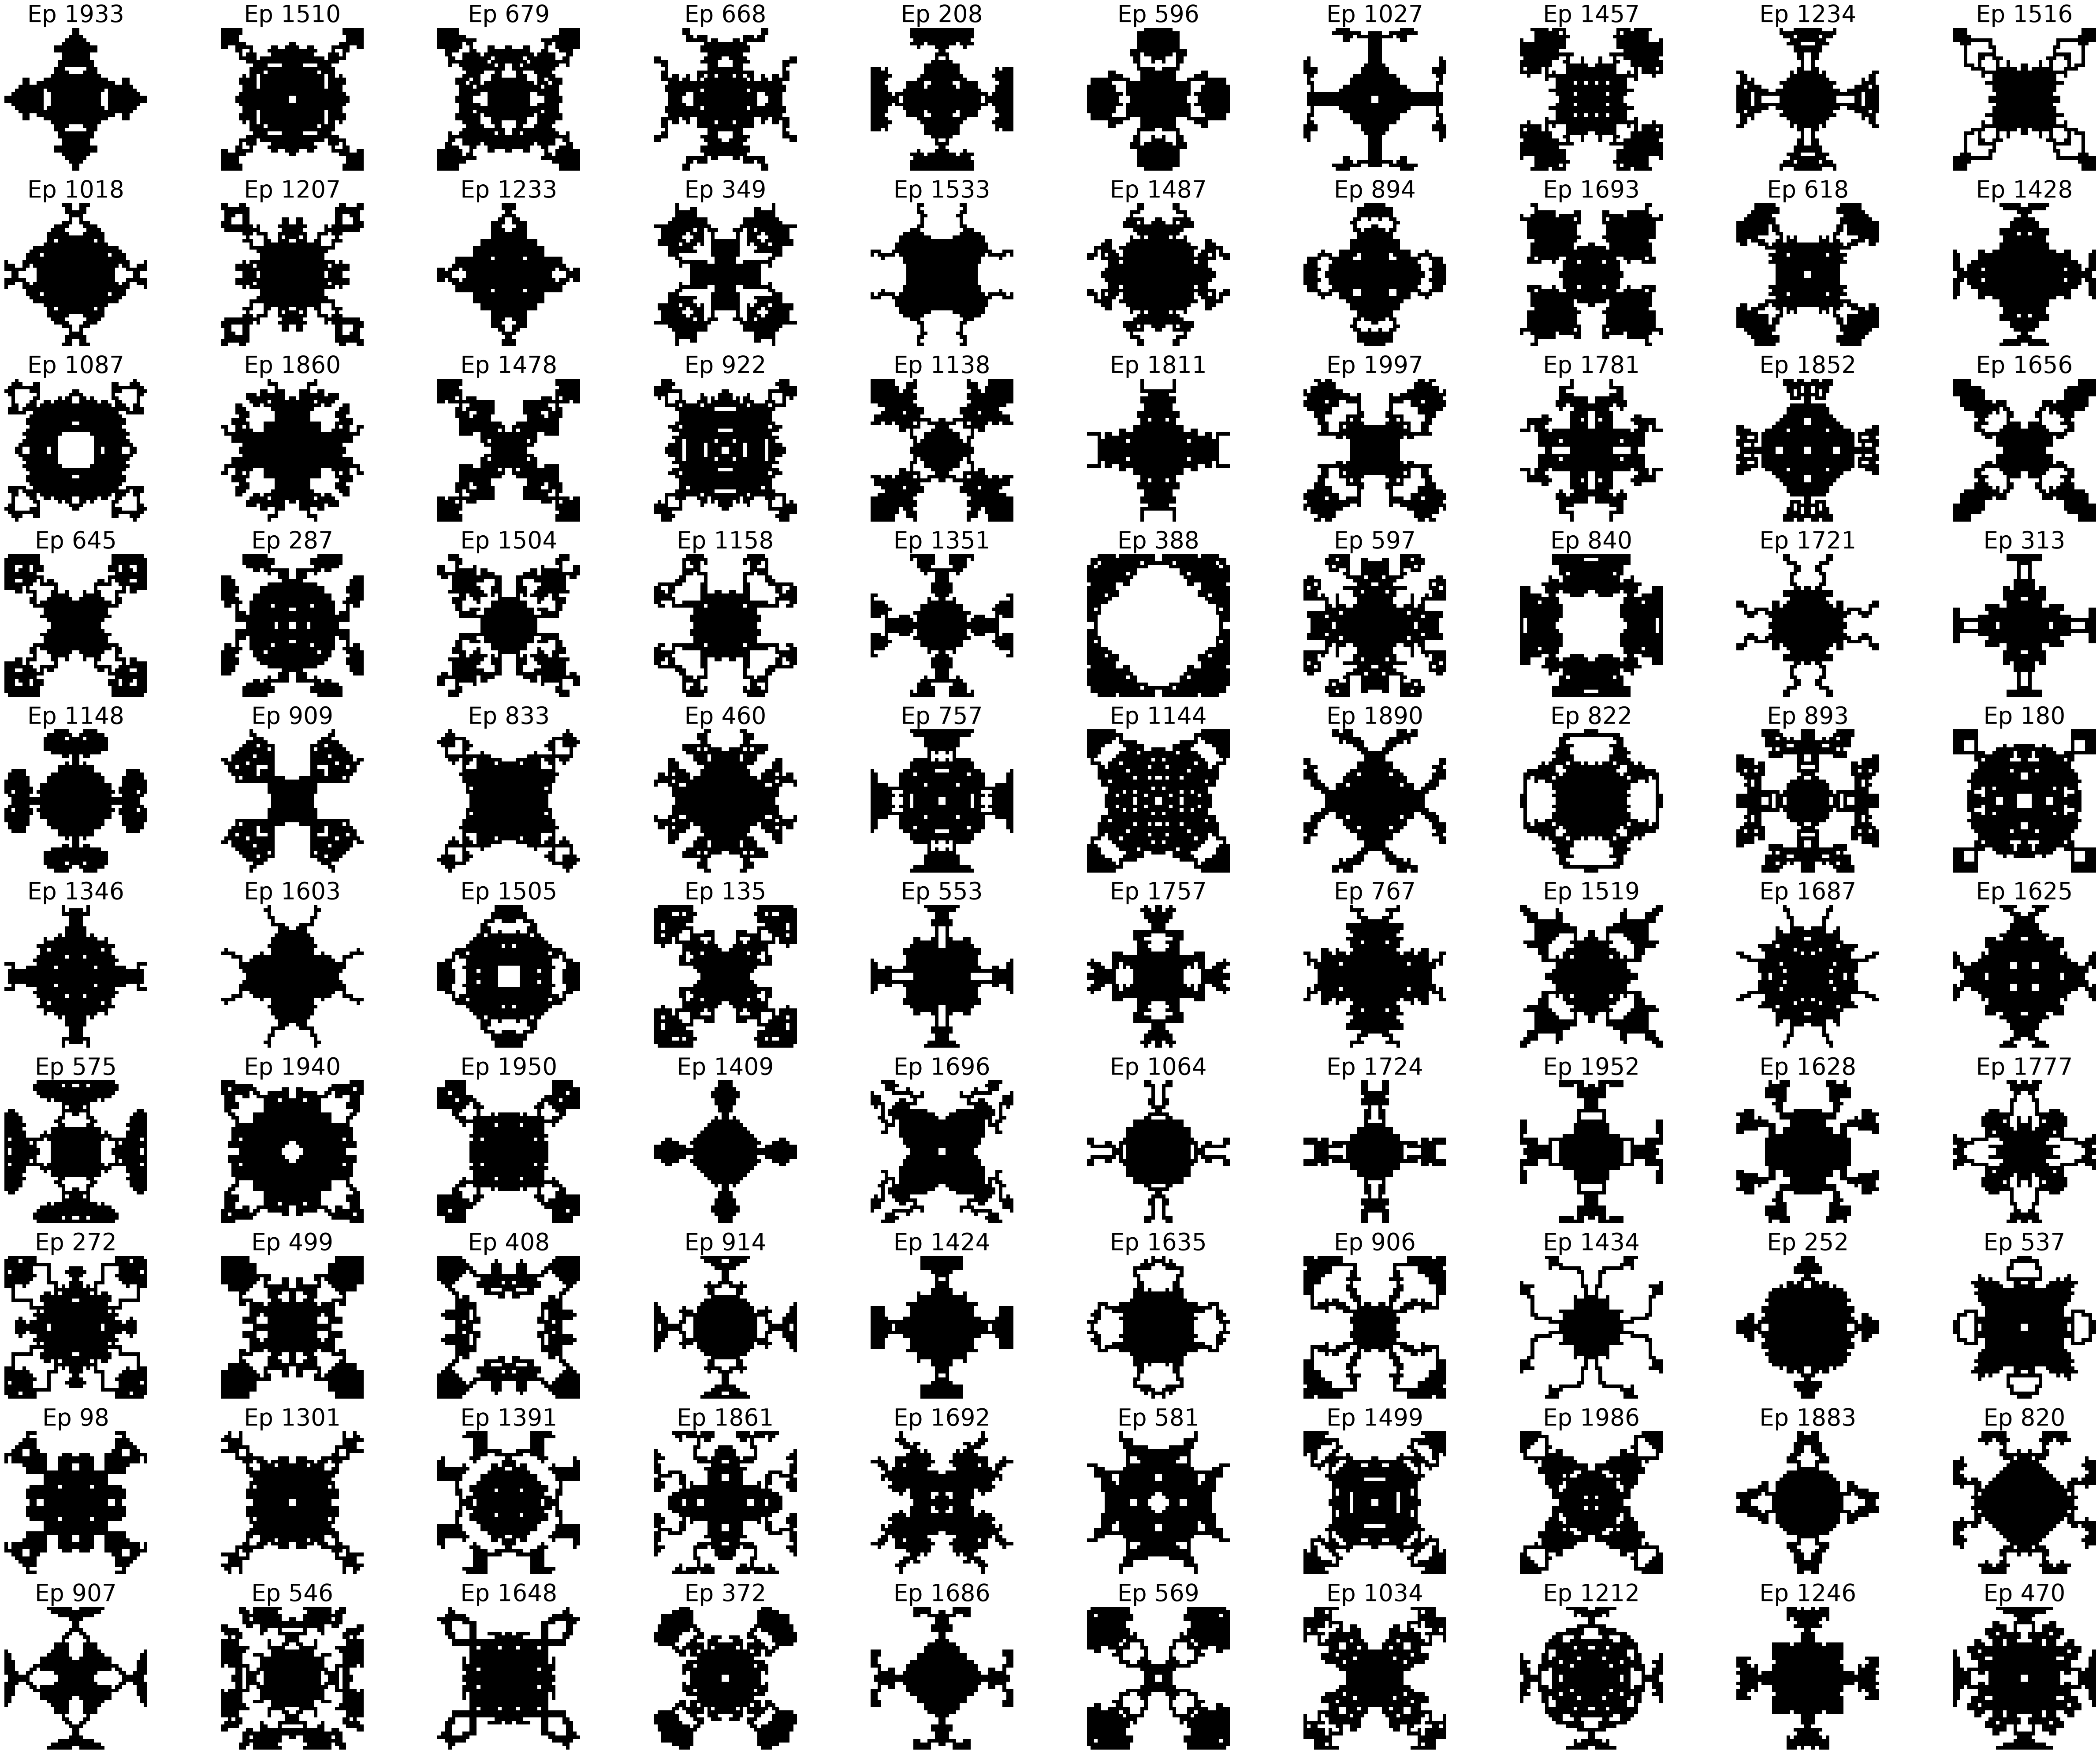

In [55]:
from utils.utils import check_4_connectivity_single_component

rng = np.random.default_rng(2)

idx = np.where(rewards > 8)[0]
rx = rng.choice(idx, 100, replace=False)

states = [val['states'] for val in loadData]
states = [np.array(state) for state in states]
states = np.array(states)[rx]

new_states = states#np.array(states)[pos_rew]

fig, axes = plt.subplots(10, 10, figsize=(50,40))
axes = axes.flatten()

for i in range(100):
    path1 = np.asarray(new_states[i], dtype=int)
    path1 = np.unique(path1, axis=0)

    fundgrid = get_fundamental_grid(20, path1)
    Fullgrid = build_p4m_structure_simple(fundgrid)
    Fullgrid = strictly_enforce_4_connectivity(Fullgrid)
    is_conn, n_grids = check_4_connectivity_single_component(Fullgrid)
    if is_conn:    
        axes[i].imshow(Fullgrid, cmap="gray", origin="lower")
        axes[i].set_title(f"Ep {rx[i]}", fontsize=38)
        axes[i].axis("off")

plt.tight_layout()
plt.show()


In [56]:
fig, axes = plt.subplots(10, 10, figsize=(40, 40),dpi=200)
axes = axes.flatten()

for i in range(100):
    r, c = divmod(i, 100)

    path1 = np.asarray(new_states[i], dtype=int)
    path1 = np.unique(path1, axis=0)

    fundgrid = get_fundamental_grid(20, path1)
    Fullgrid = build_p4m_structure_simple(fundgrid)
    Fullgrid = strictly_enforce_4_connectivity(Fullgrid)
    is_conn, n_grids = check_4_connectivity_single_component(Fullgrid)

    if is_conn:
        ax = axes[i]
        ax.imshow(Fullgrid, cmap="gray", origin="lower")
        ax.axis("off")

# for c in range(10):
#     axes[c].set_title(str(c), fontsize=44, pad=8)

for r in range(10):
    axes[r * 10].text(-0.15, 0.5, str(r),
                      transform=axes[r * 10].transAxes,
                      fontsize=44,
                      va='center',
                      ha='right')

plt.tight_layout()
#plt.savefig("SAC_DISCRETE_training_data_WO_frame_history_STATES_0.png", dpi=500, bbox_inches='tight')
plt.show()
#plt.close()


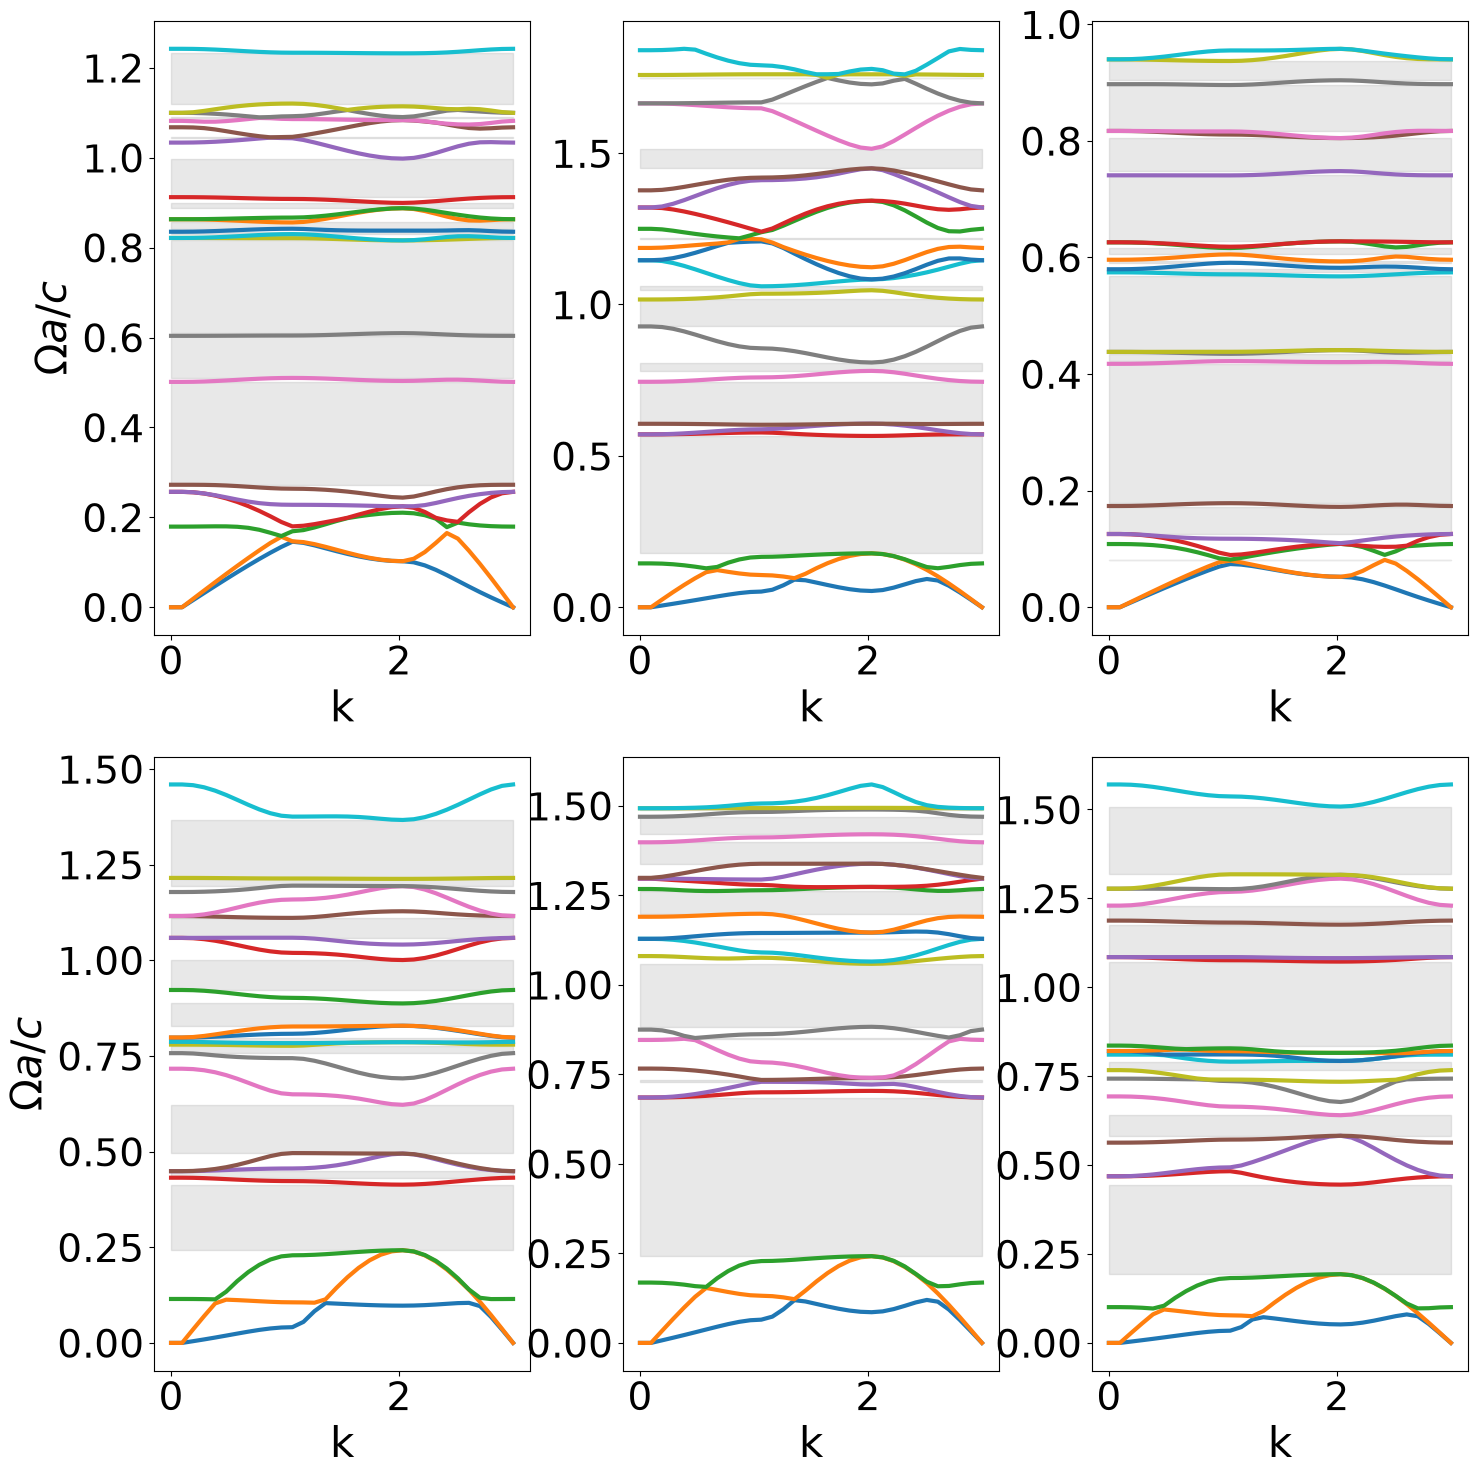

In [57]:
#Based on the index get the bandgap
import numpy as np
import matplotlib.pyplot as plt

bandgaps= [val['bandgap'] for val in loadData]
bandgaps= [np.array(bng) for bng in bandgaps]
bandgapsx = [bandgaps[i] for i in rx]
#print(np.shape(np.array(bandgaps)))
k= np.linspace(0,3,32)

#band_high3 = bandgapsx #np.array(bandgaps)[rm]#bandgapsx#

############Instead plot only selected 10 bandgaps###############
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "legend.fontsize": 14,
    "lines.linewidth": 2})

selected_idx = np.random.choice(idx,6)#[709, 1391, 1475, 1484, 1729, 1905]
fig, axes = plt.subplots(2, 3, figsize=(15, 15))
axes = axes.flatten()

for i in range(6):
    data = bandgaps[selected_idx[i]] * 0.04 / 343  # shape (32, 20)
    data_sorted = np.sort(data, axis=1)
    axes[i].plot(k, data_sorted, linewidth=3)

    for b in range(data_sorted.shape[1] - 1):
        lower = data_sorted[:, b]
        upper = data_sorted[:, b + 1]

        lower_max = np.max(lower)
        upper_min = np.min(upper)

        if upper_min > lower_max:
            axes[i].fill_between(k,lower_max, upper_min, color='gray',alpha=0.18)

    axes[i].set_xlabel("k", fontsize=30)
    if i % 3 == 0:
        axes[i].set_ylabel("$\\Omega a/c$", fontsize=30)
    else:
        axes[i].set_ylabel("")

    axes[i].tick_params(axis='both', labelsize=28)

plt.tight_layout()
#plt.savefig("updatedBandgaps_SAC_DISCRETE_training_data_WO_Bias.png", dpi=500, bbox_inches='tight')



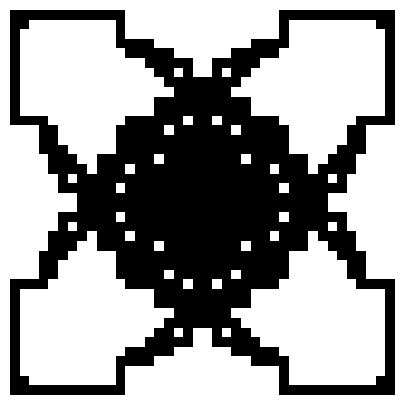

In [5]:
##plotting unit cell for the above figure to show it at the left bottom diagram
states = [val['states'] for val in loadData]
states = [np.array(state) for state in states]

plt.figure(figsize=(5,5))
for i in range(6):
    path1 = np.asarray(states[selected_idx[i]], dtype=int)
    path1 = np.unique(path1, axis=0)
    
    fundgrid = get_fundamental_grid(20, path1)
    Fullgrid = build_p4m_structure_simple(fundgrid)
    Fullgrid = strictly_enforce_4_connectivity(Fullgrid)
    is_conn, n_grids = check_4_connectivity_single_component(Fullgrid)
    
    plt.imshow(Fullgrid, cmap='gray')
    plt.xticks([])
    plt.yticks([])
    
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['bottom'].set_visible(False)
    plt.gca().spines['left'].set_visible(False)
    
    plt.savefig(f"unit_cell_{selected_idx[i]}.png", dpi=400, bbox_inches='tight')


[np.int64(5), np.int64(8), np.int64(18), np.int64(9), np.int64(13), np.int64(2), np.int64(11), np.int64(5), np.int64(11), np.int64(9), np.int64(2), np.int64(16), np.int64(17), np.int64(2), np.int64(12), np.int64(9), np.int64(8), np.int64(5), np.int64(5), np.int64(13), np.int64(11), np.int64(14), np.int64(2), np.int64(9), np.int64(14), np.int64(2), np.int64(5), np.int64(13), np.int64(2), np.int64(8), np.int64(14), np.int64(11), np.int64(16), np.int64(2), np.int64(11), np.int64(13), np.int64(5), np.int64(2), np.int64(5), np.int64(5), np.int64(17), np.int64(2), np.int64(11), np.int64(13), np.int64(9), np.int64(14), np.int64(4), np.int64(8), np.int64(13), np.int64(5), np.int64(13), np.int64(4), np.int64(5), np.int64(18), np.int64(2), np.int64(5), np.int64(5), np.int64(17), np.int64(2), np.int64(5), np.int64(9), np.int64(2), np.int64(6), np.int64(9), np.int64(11), np.int64(2), np.int64(11), np.int64(5), np.int64(2), np.int64(8), np.int64(18), np.int64(5), np.int64(15), np.int64(2), np.int64

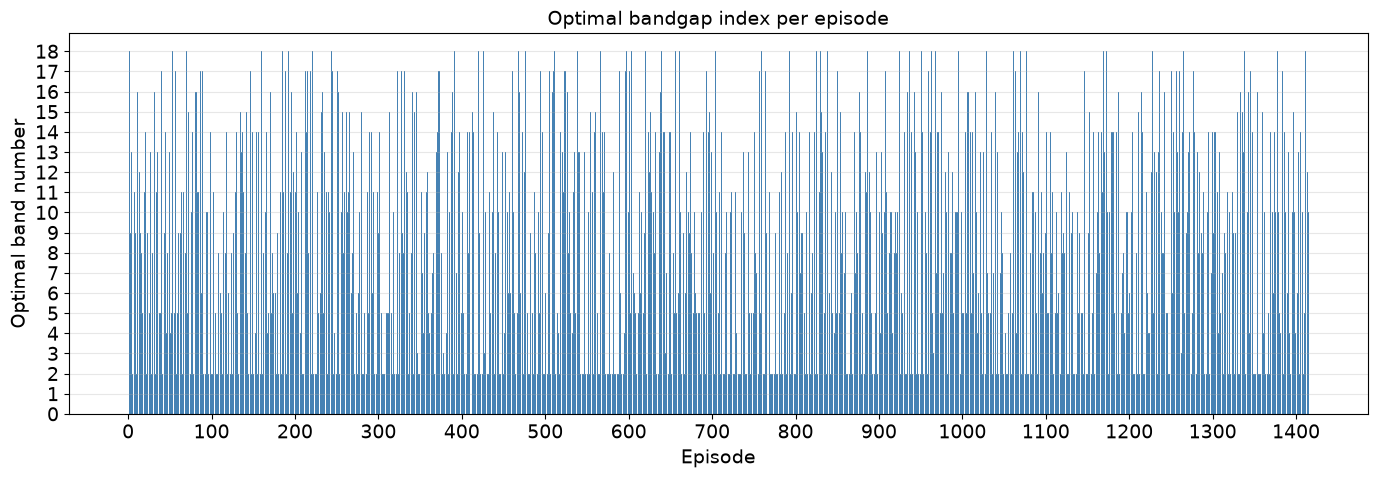

In [58]:
import numpy as np
import matplotlib.pyplot as plt

bandgaps= [val['bandgap'] for val in loadData]
bandgaps= [np.array(x) for x in bandgaps]

idx= np.where(rewards >0)[0]
bandgaps = [bandgaps[i] for i in idx]
#idx = np.random.choice(idx, 100)
#bandgaps = np.array(bandgaps)
#print((bandgaps[:10]))

best_indices = []
best_rewards = []
valid_episodes = []

for j in range(len(bandgaps)):

    data = bandgaps[j]

    # Skip invalid dispersion data
    if data.shape != (32, 20):
        print(f"Skipping episode {j}: shape {data.shape}")
        continue

    kk = []

    for i in range(19):
        J = (np.min(data[:, i+1]) -
             np.max(data[:, i])) / 1000

        kk.append(J)

    max_J = np.max(kk)
    best_i = np.argmax(kk)

    best_indices.append(best_i)
    best_rewards.append(max_J)
    valid_episodes.append(j)

print(best_indices)

plt.figure(figsize=(14, 5))

plt.bar(valid_episodes, best_indices, width=0.8, color='steelblue')

plt.xlabel('Episode')
plt.ylabel('Optimal band number')
plt.title('Optimal bandgap index per episode')

plt.xticks(np.arange(0, max(valid_episodes)+1, 100))
plt.yticks(range(19))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 15))
axes = axes.flatten()

for i in range(6):
    data = bandgaps[selected_idx[i]] * 0.04 / 343  # shape (32, 20)
    data_sorted = np.sort(data, axis=1)
    axes[i].plot(k, data_sorted, linewidth=3)

    for b in range(data_sorted.shape[1] - 1):
        lower = data_sorted[:, b]
        upper = data_sorted[:, b + 1]

        lower_max = np.max(lower)
        upper_min = np.min(upper)

        if upper_min > lower_max:
            axes[i].fill_between(k,lower_max, upper_min, color='gray',alpha=0.18)

    axes[i].set_xlabel("k", fontsize=30)
    if i % 3 == 0:
        axes[i].set_ylabel("$\\Omega a/c$", fontsize=30)
    else:
        axes[i].set_ylabel("")

    axes[i].tick_params(axis='both', labelsize=28)

plt.tight_layout()

[14, 125, 127, 200, 259, 262, 340, 365, 401, 409, 481, 492, 525, 558, 600, 610, 620, 638, 644, 682, 687, 854, 887, 904, 909, 967, 998, 1007, 1048, 1090, 1302, 1382, 1437]


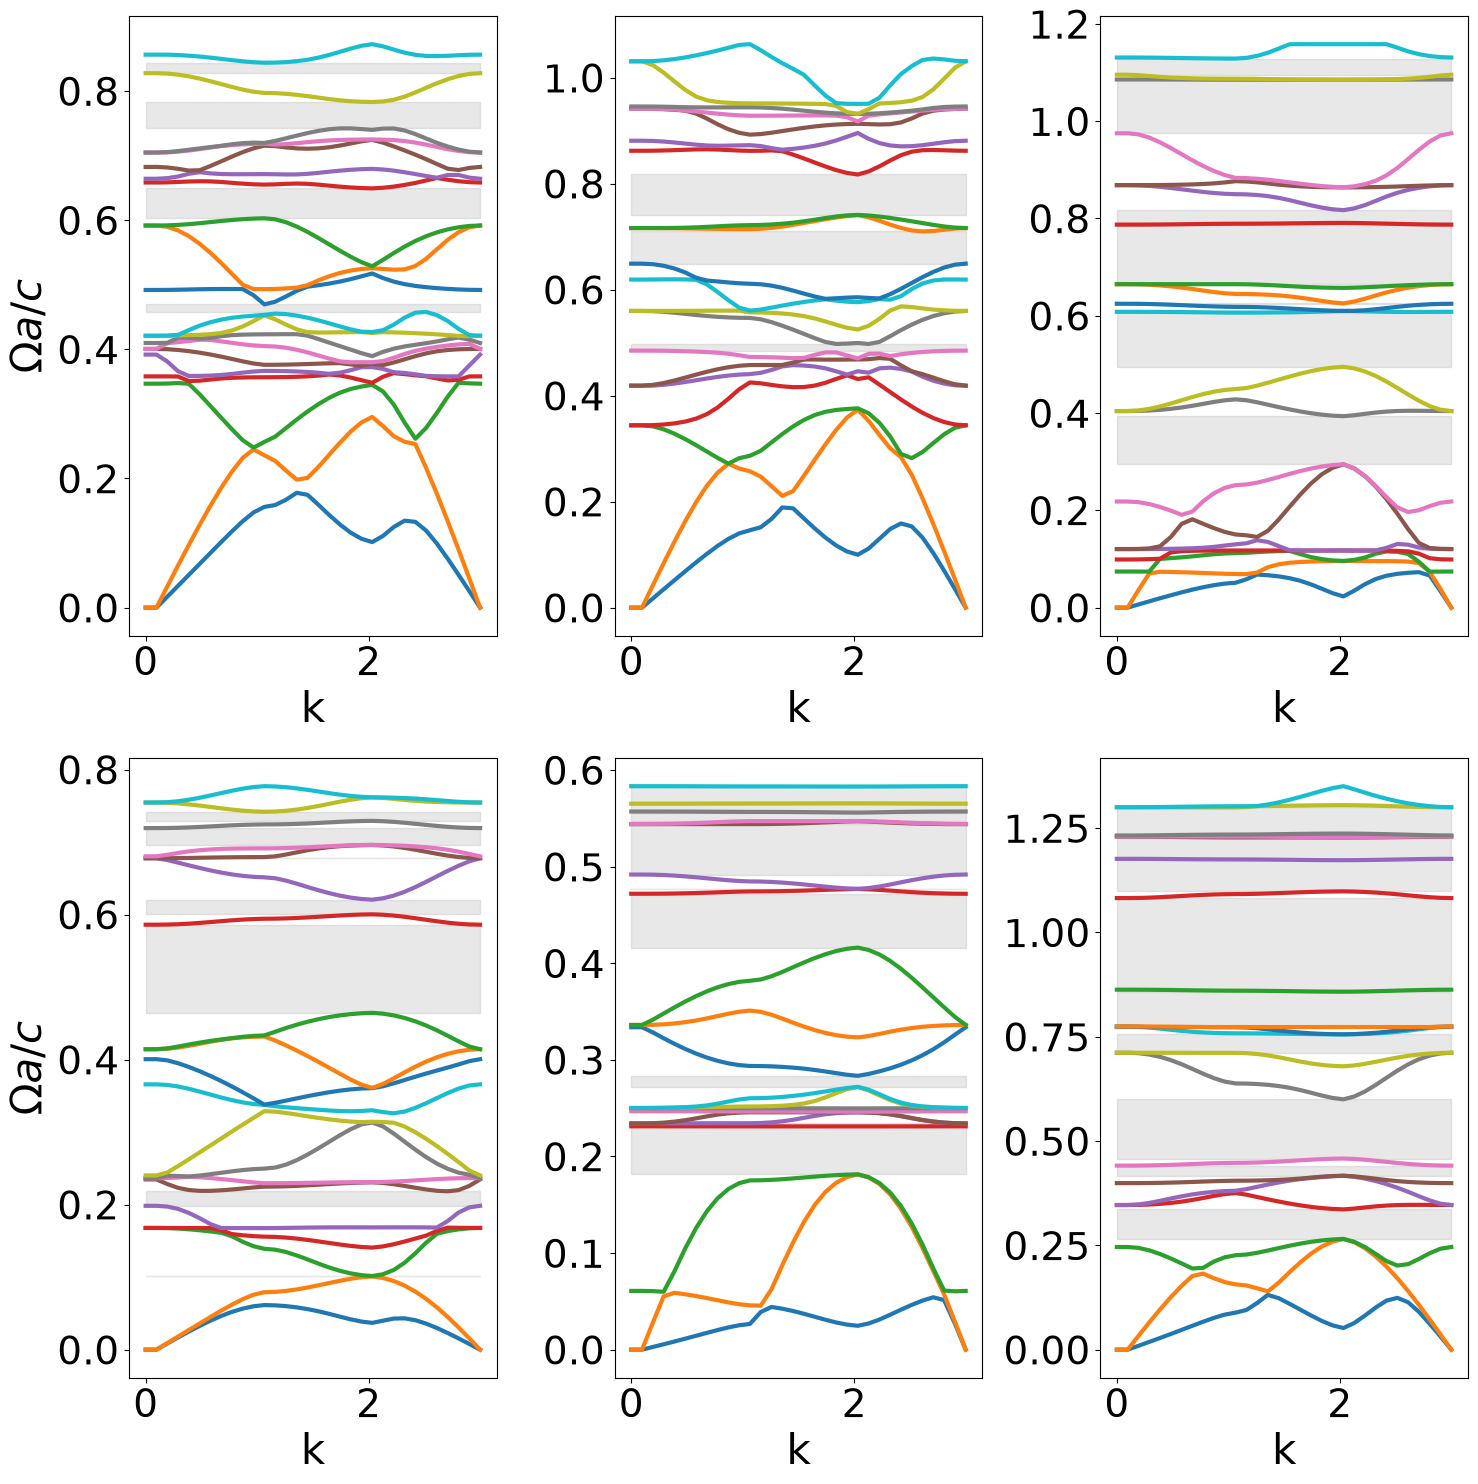

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(15, 15))
axes = axes.flatten()

episodes = [ep for ep, idx in zip(valid_episodes, best_indices) if idx == 12]
print(episodes)


for i in range(6):
    data = bandgaps[episodes[i]] * 0.04 / 343  # shape (32, 20)
    data_sorted = np.sort(data, axis=1)
    axes[i].plot(k, data_sorted, linewidth=3)

    for b in range(data_sorted.shape[1] - 1):
        lower = data_sorted[:, b]
        upper = data_sorted[:, b + 1]

        lower_max = np.max(lower)
        upper_min = np.min(upper)

        if upper_min > lower_max:
            axes[i].fill_between(k,lower_max, upper_min, color='gray',alpha=0.18)

    axes[i].set_xlabel("k", fontsize=30)
    if i % 3 == 0:
        axes[i].set_ylabel("$\\Omega a/c$", fontsize=30)
    else:
        axes[i].set_ylabel("")

    axes[i].tick_params(axis='both', labelsize=28)

plt.tight_layout()